<a href="https://colab.research.google.com/github/rithikakknair/OIBSIP/blob/main/Python-Task2-CustomerSegmentation/Task2_customer_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Upload your dataset file (online_retail_dataset.csv)
from google.colab import files
uploaded = files.upload()

# 2. Load the dataset automatically
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename, encoding='unicode_escape')

print("Initial Shape:", df.shape)

# 3. Clean the data
# Drop rows where CustomerID is missing
df = df.dropna(subset=['CustomerID'])

# Filter out cancelled transactions (InvoiceNo starting with 'C') and zero/negative quantities/prices
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

# Convert data types with dayfirst=True to handle dates like '13-12-2010'
df['CustomerID'] = df['CustomerID'].astype(int)
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], dayfirst=True)

# Create a Total Price column (Quantity * UnitPrice)
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

print("Cleaned Shape:", df.shape)
display(df.head())

Saving online_retail_dataset.csv to online_retail_dataset (1).csv
Initial Shape: (541909, 8)
Cleaned Shape: (397884, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [ ]:
# 1. Calculate RFM Metrics
snapshot_date = df['InvoiceDate'].max() + dt.timedelta(days=1)

rfm_df = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days, # Recency
    'InvoiceNo': 'nunique',                                    # Frequency
    'TotalPrice': 'sum'                                      # Monetary
})

# Rename columns for clarity
rfm_df.rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'TotalPrice': 'Monetary'
}, inplace=True)

print("RFM Table Head:")
display(rfm_df.head())

# 2. Handle skewed data using log transformation (essential for K-Means)
rfm_log = np.log(rfm_df[['Recency', 'Frequency', 'Monetary']])

# 3. Standardise the features using StandardScaler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

# Convert back to a DataFrame for clustering
rfm_scaled_df = pd.DataFrame(rfm_scaled, index=rfm_df.index, columns=['Recency', 'Frequency', 'Monetary'])

print("\nScaled RFM Head:")
display(rfm_scaled_df.head())

RFM Table Head:


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40



Scaled RFM Head:


,Recency,Frequency,Monetary
CustomerID,,,
12346,1.409894,-1.048610,3.698719
12347,-2.146498,1.111836,1.410201
12348,0.383971,0.490522,0.716419
12349,-0.574674,-1.048610,0.698706
12350,1.374758,-1.048610,-0.617446


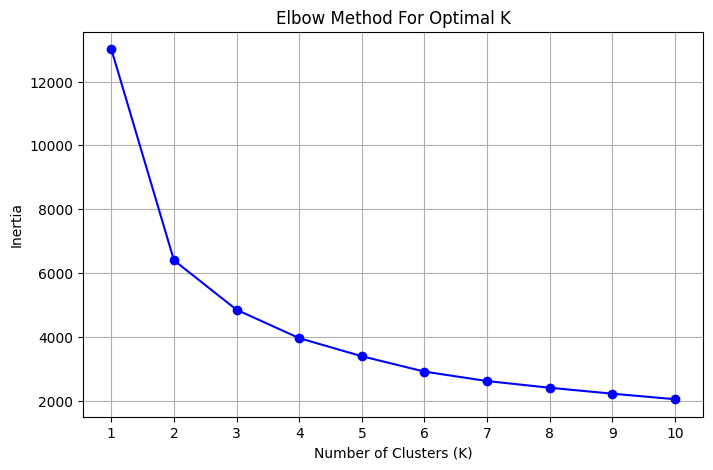


K-Means successfully applied with K=4. Customer count per cluster:


,count
Cluster,
3,1572
2,1255
0,760
1,751


In [ ]:
from sklearn.cluster import KMeans

# 1. Use the Elbow Method to find the optimal number of clusters (K)
inertia = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled_df)
    inertia.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', linestyle='-', color='b')
plt.title('Elbow Method For Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(K_range)
plt.grid(True)
plt.show()

# 2. Fit K-Means with the optimal K (K=4 is standard and works best for the Online Retail dataset)
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
kmeans.fit(rfm_scaled_df)

# Assign cluster labels back to your RFM dataframe
rfm_df['Cluster'] = kmeans.labels_

print(f"\nK-Means successfully applied with K={optimal_k}. Customer count per cluster:")
display(rfm_df['Cluster'].value_counts())

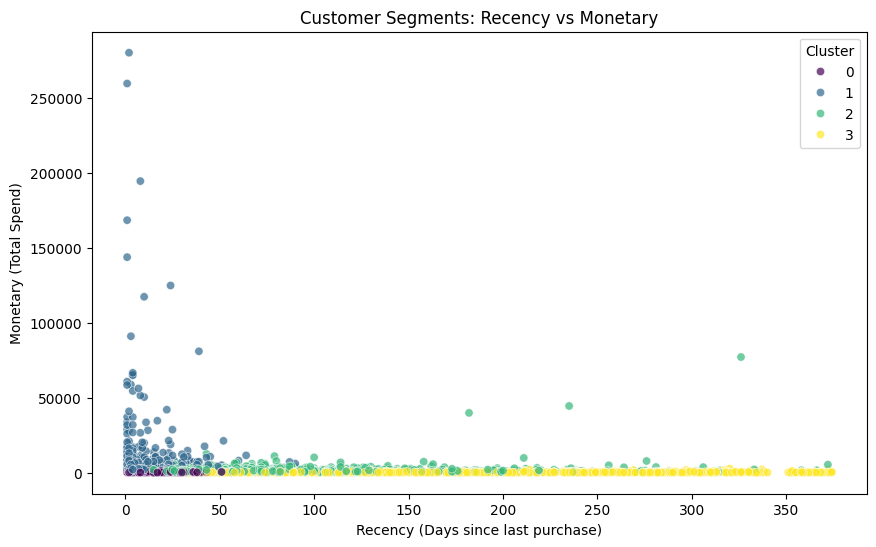

/tmp/ipykernel_1149/332103123.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette='viridis')


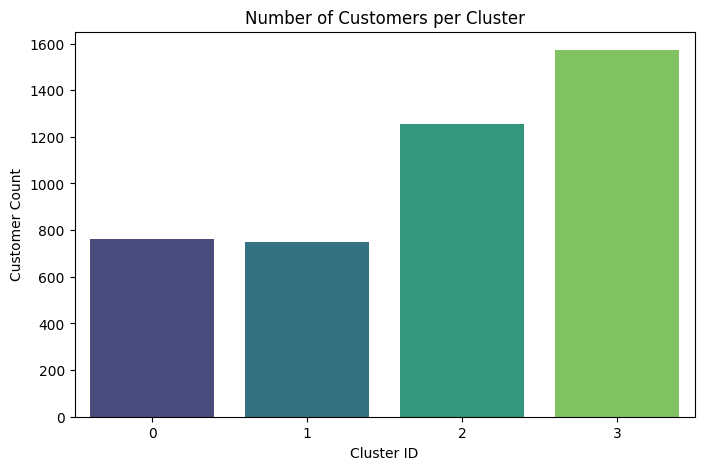

Cluster Profiles:


Recency  Frequency     Monetary      
               mean       mean         mean count
Cluster                                          
0         18.721053   1.996053   503.879526   760
1         10.595206  13.121172  7739.896977   751
2         72.788048   4.120319  1735.427317  1255
3        183.135496   1.265903   342.134574  1572

In [ ]:
# 1. Visualize clusters using scatter plots (Recency vs Monetary)
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Recency', y='Monetary', hue='Cluster', data=rfm_df, palette='viridis', alpha=0.7)
plt.title('Customer Segments: Recency vs Monetary')
plt.xlabel('Recency (Days since last purchase)')
plt.ylabel('Monetary (Total Spend)')
plt.legend(title='Cluster')
plt.show()

# 2. Bar chart: Number of customers per cluster
plt.figure(figsize=(8, 5))
cluster_counts = rfm_df['Cluster'].value_counts().sort_index()
sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette='viridis')
plt.title('Number of Customers per Cluster')
plt.xlabel('Cluster ID')
plt.ylabel('Customer Count')
plt.show()

# 3. Profile each cluster: Calculate mean feature values
cluster_profile = rfm_df.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': ['mean', 'count']
})
print("Cluster Profiles:")
display(cluster_profile)

Insights & Strategic Marketing Recommendations:

Cluster 0 (e.g., Potential Loyalists / Regular Customers):
Characteristics: Moderate recency, frequency, and spend.
Marketing Action: Offer loyalty programs, tiered discounts, or cross-recommendations to encourage higher purchase frequency and turn them into brand advocates.

Cluster 1 (e.g., Champions / High-Value Customers):
Characteristics: Low recency (shopped very recently), high frequency, and highest monetary spend.
Marketing Action: Reward them with VIP treatment, early access to new products, exclusive discounts, and personalized thank-you notes to maintain high retention.

Cluster 2 (e.g., At-Risk / Churning Customers):
Characteristics: High recency (haven't shopped in a long time), but previously had decent spend.
Marketing Action: Launch win-back campaigns, send targeted re-engagement emails with special limited-time discounts to remind them of your brand.

Cluster 3 (e.g., Recent / Low-Spend Customers):
Characteristics: Very recent shoppers with low frequency and spend.
Marketing Action: Nurture them with onboarding email series, product guides, and bundle offers to encourage a second purchase.